In [1]:
library(dplyr)
## visualization
library(ggplot2)
library(ggplot2)
library(gridExtra)
library(dplyr)
library(ggplot2)
library(cowplot)


Attaching package: ‘dplyr’


The following objects are masked from ‘package:stats’:

    filter, lag


The following objects are masked from ‘package:base’:

    intersect, setdiff, setequal, union



Attaching package: ‘gridExtra’


The following object is masked from ‘package:dplyr’:

    combine




In [2]:
setwd("/home/liuxuan/metadata/10-10/PRJNA786326/")
initial_meta <- read.csv("SraRunTable.csv", header = TRUE)
head(initial_meta)
colnames(initial_meta)

,Run,Assay.Type,AvgSpotLen,Bases,BioProject,BioSample,BioSampleModel,Bytes,Center.Name,Collection_Date,⋯,LibraryLayout,LibrarySelection,LibrarySource,Organism,Platform,ReleaseDate,create_date,version,Sample.Name,SRA.Study
,<chr>,<chr>,<int>,<int>,<chr>,<chr>,<chr>,<int>,<chr>,<chr>,⋯,<chr>,<chr>,<chr>,<chr>,<chr>,<chr>,<chr>,<int>,<chr>,<chr>
1,SRR17134355,AMPLICON,489,30310420,PRJNA786326,SAMN23667373,"MIMARKS.survey,MIGS/MIMS/MIMARKS.human-oral",19103399,PEKING UNIVERSITY,2018-10-16,⋯,PAIRED,PCR,GENOMIC,human oral metagenome,ILLUMINA,2021-12-23T00:00:00Z,2021-12-05T10:29:00Z,1,BJ_109GCFP3,SRP349293
2,SRR17134356,AMPLICON,489,30480390,PRJNA786326,SAMN23667372,"MIMARKS.survey,MIGS/MIMS/MIMARKS.human-oral",19073617,PEKING UNIVERSITY,2018-07-16,⋯,PAIRED,PCR,GENOMIC,human oral metagenome,ILLUMINA,2021-12-23T00:00:00Z,2021-12-05T10:29:00Z,1,BJ_95GCFP3,SRP349293
3,SRR17134357,AMPLICON,497,30560360,PRJNA786326,SAMN23667371,"MIMARKS.survey,MIGS/MIMS/MIMARKS.human-oral",17280663,PEKING UNIVERSITY,2018-05-16,⋯,PAIRED,PCR,GENOMIC,human oral metagenome,ILLUMINA,2021-12-23T00:00:00Z,2021-12-05T10:29:00Z,1,BJ_63GCFP3,SRP349293
4,SRR17134358,AMPLICON,498,29585100,PRJNA786326,SAMN23667424,"MIMARKS.survey,MIGS/MIMS/MIMARKS.human-oral",16018198,PEKING UNIVERSITY,2019-01-26,⋯,PAIRED,PCR,GENOMIC,human oral metagenome,ILLUMINA,2021-12-23T00:00:00Z,2021-12-05T10:29:00Z,1,BJ_77GCFP9,SRP349293
5,SRR17134359,AMPLICON,498,30810450,PRJNA786326,SAMN23667370,"MIMARKS.survey,MIGS/MIMS/MIMARKS.human-oral",16407200,PEKING UNIVERSITY,2018-04-16,⋯,PAIRED,PCR,GENOMIC,human oral metagenome,ILLUMINA,2021-12-23T00:00:00Z,2021-12-05T10:29:00Z,1,BJ_51GCFP3,SRP349293
6,SRR17134360,AMPLICON,498,30280440,PRJNA786326,SAMN23667423,"MIMARKS.survey,MIGS/MIMS/MIMARKS.human-oral",16414634,PEKING UNIVERSITY,2019-01-10,⋯,PAIRED,PCR,GENOMIC,human oral metagenome,ILLUMINA,2021-12-23T00:00:00Z,2021-12-05T10:29:00Z,1,BJ_71GCFP9,SRP349293


[1] "Run"                            "Assay.Type"                    
 [3] "AvgSpotLen"                     "Bases"                         
 [5] "BioProject"                     "BioSample"                     
 [7] "BioSampleModel"                 "Bytes"                         
 [9] "Center.Name"                    "Collection_Date"               
[11] "Consent"                        "DATASTORE.filetype"            
[13] "DATASTORE.provider"             "DATASTORE.region"              
[15] "env_broad_scale"                "env_local_scale"               
[17] "env_medium"                     "Experiment"                    
[19] "geo_loc_name_country"           "geo_loc_name_country_continent"
[21] "geo_loc_name"                   "HOST"                          
[23] "Instrument"                     "lat_lon"                       
[25] "Library.Name"                   "LibraryLayout"                 
[27] "LibrarySelection"               "LibrarySource"                 
[29] "Organism"                       "Platform"                      
[31] "ReleaseDate"                    "create_date"                   
[33] "version"                        "Sample.Name"                   
[35] "SRA.Study"

In [7]:
uniform_meta <- data.frame(
    BioProject = initial_meta$BioProject,
    Run = initial_meta$Run,
    sample_name = initial_meta$'Sample.Name',
    Age = NA,
    BMI = NA,
    Sex = NA,
    Region = 'V3–V4',
    Platform = initial_meta$Platform,
    Country = initial_meta$geo_loc_name_country,
    Site = 'gingival crevicular fluid',
    public_time = initial_meta$ReleaseDate,
    PCR_primers = 'F: GTGCCAGCMGCCGCGGTAA; R: GGACTACHVGGGTWTCTAAT',
    title = "Microbiota in Gingival Crevicular Fluid Before and After Mechanical Debridement With Antimicrobial Photodynamic Therapy in Peri-Implantitis",
    Disease_study = "YES",
    Status = NA,
    matched_samples = 'NO')

In [8]:
print(length(unique(uniform_meta$Run)))
print(length(unique(uniform_meta$sample_name)))

[1] 61
[1] 61


In [9]:
head(uniform_meta)

,BioProject,Run,sample_name,Age,BMI,Sex,Region,Platform,Country,Site,public_time,PCR_primers,title,Disease_study,Status,matched_samples
,<chr>,<chr>,<chr>,<lgl>,<lgl>,<lgl>,<chr>,<chr>,<chr>,<chr>,<chr>,<chr>,<chr>,<chr>,<lgl>,<chr>
1,PRJNA786326,SRR17134355,BJ_109GCFP3,NA,NA,NA,V3–V4,ILLUMINA,China,gingival crevicular fluid,2021-12-23T00:00:00Z,F: GTGCCAGCMGCCGCGGTAA; R: GGACTACHVGGGTWTCTAAT,Microbiota in Gingival Crevicular Fluid Before and After Mechanical Debridement With Antimicrobial Photodynamic Therapy in Peri-Implantitis,YES,NA,NO
2,PRJNA786326,SRR17134356,BJ_95GCFP3,NA,NA,NA,V3–V4,ILLUMINA,China,gingival crevicular fluid,2021-12-23T00:00:00Z,F: GTGCCAGCMGCCGCGGTAA; R: GGACTACHVGGGTWTCTAAT,Microbiota in Gingival Crevicular Fluid Before and After Mechanical Debridement With Antimicrobial Photodynamic Therapy in Peri-Implantitis,YES,NA,NO
3,PRJNA786326,SRR17134357,BJ_63GCFP3,NA,NA,NA,V3–V4,ILLUMINA,China,gingival crevicular fluid,2021-12-23T00:00:00Z,F: GTGCCAGCMGCCGCGGTAA; R: GGACTACHVGGGTWTCTAAT,Microbiota in Gingival Crevicular Fluid Before and After Mechanical Debridement With Antimicrobial Photodynamic Therapy in Peri-Implantitis,YES,NA,NO
4,PRJNA786326,SRR17134358,BJ_77GCFP9,NA,NA,NA,V3–V4,ILLUMINA,China,gingival crevicular fluid,2021-12-23T00:00:00Z,F: GTGCCAGCMGCCGCGGTAA; R: GGACTACHVGGGTWTCTAAT,Microbiota in Gingival Crevicular Fluid Before and After Mechanical Debridement With Antimicrobial Photodynamic Therapy in Peri-Implantitis,YES,NA,NO
5,PRJNA786326,SRR17134359,BJ_51GCFP3,NA,NA,NA,V3–V4,ILLUMINA,China,gingival crevicular fluid,2021-12-23T00:00:00Z,F: GTGCCAGCMGCCGCGGTAA; R: GGACTACHVGGGTWTCTAAT,Microbiota in Gingival Crevicular Fluid Before and After Mechanical Debridement With Antimicrobial Photodynamic Therapy in Peri-Implantitis,YES,NA,NO
6,PRJNA786326,SRR17134360,BJ_71GCFP9,NA,NA,NA,V3–V4,ILLUMINA,China,gingival crevicular fluid,2021-12-23T00:00:00Z,F: GTGCCAGCMGCCGCGGTAA; R: GGACTACHVGGGTWTCTAAT,Microbiota in Gingival Crevicular Fluid Before and After Mechanical Debridement With Antimicrobial Photodynamic Therapy in Peri-Implantitis,YES,NA,NO


Warning message in grid.Call(C_textBounds, as.graphicsAnnot(x$label), x$x, x$y, :
“conversion failure on 'V3–V4' in 'mbcsToSbcs': dot substituted for <e2>”
Warning message in grid.Call(C_textBounds, as.graphicsAnnot(x$label), x$x, x$y, :
“conversion failure on 'V3–V4' in 'mbcsToSbcs': dot substituted for <80>”
Warning message in grid.Call(C_textBounds, as.graphicsAnnot(x$label), x$x, x$y, :
“conversion failure on 'V3–V4' in 'mbcsToSbcs': dot substituted for <93>”


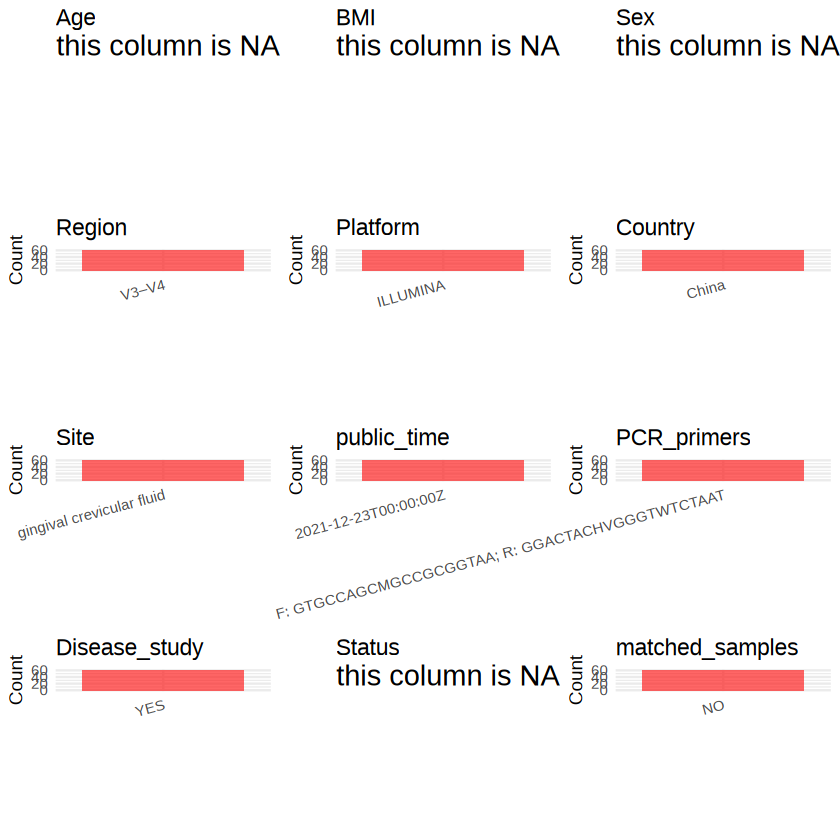

In [10]:
plot_data <- uniform_meta %>%
  select(-BioProject, -Run, -sample_name, -title)

create_simple_plots <- function(data) {
  plots <- list()
  
  for (col in colnames(data)) {
    if (all(is.na(data[[col]]))) {
      p <- ggplot() +
        annotate("text", x = 0.5, y = 0.5, label = "this column is NA", size = 6) +
        labs(title = col) +
        theme_void()
    } else if (is.numeric(data[[col]])) {
      p <- ggplot(data, aes(x = .data[[col]])) +
        geom_histogram(fill = "blue", alpha = 0.6, bins = 20, na.rm = TRUE) +
        labs(title = col) +
        theme_minimal()
    } else {
      count_data <- as.data.frame(table(data[[col]], useNA = "ifany"))
      p <- ggplot(count_data, aes(x = reorder(Var1, -Freq), y = Freq)) +
        geom_col(fill = "red", alpha = 0.6) +
        labs(title = col, x = NULL, y = "Count") +
        theme_minimal() +
        theme(axis.text.x = element_text(angle = 15, hjust = 1))
    }
    plots[[col]] <- p
  }
  return(plots)
}

plots <- create_simple_plots(plot_data)
p<-plot_grid(plots$Age, 
          plots$BMI, 
          plots$Sex, 
          plots$Region, 
          plots$Platform, 
          plots$Country, 
          plots$Site,
          plots$public_time, 
          plots$PCR_primers,
          plots$Disease_study,
          plots$Status,
          plots$matched_samples,# add 
          ncol = 3, align = "hv", axis = "lb")
p

In [11]:
uniform_meta <- uniform_meta[, c("BioProject", "Run", "sample_name", "Age", "BMI", "Sex", "Region", "Platform", "Country", "Site", "public_time", "PCR_primers", "title", "Disease_study", "Status")]
write.csv(uniform_meta, file = "/home/liuxuan/metadata/10-10/PRJNA786326/metadata.csv", quote = T)